# WDT 2021 — Original Paper Baseline Reproduction (Annotated V2)
### OT-SENTINEL | Faramondi, Flammini, Guarino & Setola (IEEE Access, 2021)

**Paper:** [A Hardware-in-the-Loop Water Distribution Testbed Dataset for Cyber-Physical Security Testing](https://doi.org/10.1109/ACCESS.2021.3109465)  
**Source:** IEEE Access, 2021, pp. 122385–122396, Section V (Machine Learning Performance Evaluation).

> **Scope: reproduce the published baseline, not the OT-SENTINEL Stage 15/16 model.**

**Method in the paper:** four original acquisitions; two *separate* binary datasets (physical and network); removal of identical records; training-fold-only standardization; K-Fold cross-validation (**fold count not stated**); KNN (**10 nearest neighbors, not 10 folds**), Random Forest (100 trees), SVM (RBF), Gaussian Naive Bayes. Evaluation: Accuracy, Precision, Recall, F1 with *attack = positive class*.

**NOT part of the paper's reported ML baseline:** Stage 15/16 XGBoost, KG, Process Mining, physical deltas, multiscale physical windows, Cyber-Physical Fusion/Alignment, 3-class labels, and Leave-One-Capture-Out. **Nuance:** the original network dataset *does* contain `num_pkts_src` and `num_pkts_dst`, defined using a 2-second traffic history; these are packet features, not cross-modal time alignment.

### Reproduction honesty / missing specifications
**See the dedicated “Paper audit — what the 2021 authors did not specify” cell below for the full documented gap list.**
- The paper does **not specify** the exact number of folds, shuffle / random seed, encoding of categorical network addresses, or every estimator default. **This notebook uses explicit documented choices**, so results are a **methodology-based reproduction**, not a guaranteed bit-for-bit reproduction.
- We exclude `Time` as an identifying field rather than feeding raw acquisition time to the classifier; how the original authors handled the time field is not specified.
- We use **four** acquisitions mentioned in the 2021 paper (`normal` and `attack_1` to `attack_3`); `attack_4` is **intentionally excluded** even though it is in your current Drive copy.
- This notebook keeps network raw data *packet-level*. It never aggregates it to seconds or aligns it with physical rows.
- This is a **binary** attack/normal experiment, not a three-class Normal/Cyber/Fault experiment.
- Full network KNN/SVM is computationally expensive. No hidden sampling is performed. The notebook has a safety gate and explains how to disable it using a high-memory environment.

## 0 · Install and environment checks
Required: Google Colab, access to your `WDT_physical` and `WDT_NETWORK` Drive folders, and sufficient Drive/Colab disk for the ~4 GB source Network CSVs plus intermediate Parquet files.

In [2]:
%pip -q install "duckdb>=1.1,<2" "pyarrow>=17,<25" "scikit-learn>=1.4,<2" "pandas>=2,<3" matplotlib

In [3]:
import os, json, sys, time, gc, hashlib, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb, pyarrow as pa, pyarrow.parquet as pq
from IPython.display import display
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from google.colab import drive
from datetime import datetime, timezone

drive.mount('/content/drive')
print('Versions:', {'python':sys.version.split()[0], 'pandas':pd.__version__,
                    'sklearn':__import__('sklearn').__version__, 'duckdb':duckdb.__version__})

Mounted at /content/drive
Versions: {'python': '3.13.16', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'duckdb': '1.3.2'}


## 1 · Reproduction settings and **original** Drive sources
The **paper** states **K-Folds cross-validation** but does not give the number of folds. Its **`k=10` means 10 neighbors for KNN**, NOT 10 CV folds (Section V-B, p. 122394). `N_SPLITS=5`, `shuffle=True`, and seed 42 below are **our disclosed implementation choices**. You may run a **separate sensitivity check** with 10 folds, but must not claim that 10-fold CV was specified by the authors.

## Paper audit — **what the 2021 authors did not specify** (read before running)

> **Important correction: `k=10` is the number of nearest neighbors in KNN, NOT the number of cross-validation folds.** In Section V-B (IEEE Access, pp. 122393–122394), the paper says **K-Folds cross-validation** but gives **no exact fold count**. Source: [original paper, Section V](https://www.iris.unicampus.it/retrieve/961c36f4-1aff-4df4-adfc-b4486259f7c8/20.500.12610-65142.pdf).

**The actual paper-based experiment:** merge four original acquisitions into **one physical dataset** and **one network dataset**, remove identical records, standardize from the training fold only, then evaluate **KNN (10 neighbors), RF (100 trees), SVM (RBF) and Gaussian NB** independently on each dataset using **binary normal/attack labels**.

**No Cyber-Physical Fusion or cross-modal Alignment is implemented or described in its reported baseline.** The authors discuss that both modalities are necessary for more complete detection, but do **not** publish an Early/Late Fusion model or a physical ↔ packet timestamp matching algorithm. The network features `num_pkts_src` and `num_pkts_dst` count packets in the **preceding 2 seconds** (Section IV-C); that is a **network-only time-derived feature**, not a Physical–Network alignment method.

### Explicitly unspecified or insufficiently documented in the paper

| Item | What is (not) stated in the paper | What **this notebook** chooses / implication |
|---|---|---|
| **Number of CV folds** | Says *K-Folds*, **does not state K** | `N_SPLITS=5` — our assumption; **not claimed as authors' value** |
| **Shuffle / random seed / exact fold indices** | Not reported | `shuffle=True`, `seed=42` — our reproducible choices |
| **K-Fold variant** | Does not say if stratified, grouped, or acquisition-aware | Plain `KFold`; not GroupKFold/LOCO, may mix neighboring time points |
| **Treatment of time column** | Not explicit whether timestamp entered the ML feature set | Exclude `Time` to avoid an acquisition identifier; disclosed deviation/choice |
| **Exact duplicate definition & operation order** | Says remove *identical records*; no complete duplicate key or exact pre-CV order | Deduplicate feature values **plus binary label**, excluding Time, before CV |
| **Network categorical encoding** | No recipe for MAC/IP/protocol/flags conversion to numeric ML inputs | Train-fold `OrdinalEncoder`; affects paper-vs-reproduction comparison |
| **Missing/invalid-value policy** | No explicit imputation/drop policy | Stop on missing numeric features rather than invent an imputation rule |
| **Other model hyperparameters** | Specifies only KNN `k=10`, RF `100 trees`, SVM `RBF`, Gaussian NB; not full parameter sets | Use scikit-learn defaults for all unspecified settings (plus RF seed) |
| **Software versions and operating environment** | Mentions scikit-learn but not the complete reproducible environment | Record current package versions in outputs |
| **Aggregation of CV metrics** | Table 6 has Accuracy/Precision/Recall/F1, without full fold-level reporting | Report pooled out-of-fold metrics; this may differ from mean of fold scores |
| **Physical ↔ Network time synchronization** | No cross-modal matching, clock-offset, timezone, or event-alignment method specified for ML baseline | **Not performed**; dataset modalities are trained separately |
| **Fusion strategy** | Concludes combining modalities is desirable; no implemented fusion experiment in Table 6 | **Not performed**; future OT-SENTINEL extension, not paper reproduction |

### What **is** explicitly specified (do not confuse these)

- **`k=10` = KNN neighbors; `n_estimators=100` = RF trees.** These are **not** the CV fold count.
- The two datasets are evaluated **separately** (Section V-B, Table 6).
- Standardization uses **training-only** mean and variance for each test fold (Section V-B).
- Normal is the negative class and attack is the positive class (Section V-C).
- The provided dataset has `normal` + `attack_1/2/3` and matching `phy_` captures (Section IV-E), **not** `attack_4` in the 2021 original report.

**Reporting rule:** label outcomes *paper-guided methodology reproduction*, **not an exact author-code replication**, until unspecified details are resolved. Changing `N_SPLITS` to 10 is an **additional sensitivity experiment**, not “following the paper exactly.”


In [4]:
# === Explicit reproducibility settings ===
N_SPLITS=5                # OUR CHOICE, NOT paper-specified: KNN k=10 is neighbors, NOT folds.
KF_SHUFFLE=True           # ASSUMPTION: not specified in the paper.
RANDOM_STATE=42           # ASSUMPTION: not specified in the paper.
NETWORK_CHUNK_SIZE=120_000
MAX_NETWORK_ML_ROWS=350_000
ALLOW_EXPENSIVE_NETWORK_ML=False  # Set True only if enough RAM/compute for full SVM and KNN.
RUN_NETWORK_EXTRACTION=True        # Reads ALL original network rows, no sampling.

CAPS=['norm','att_1','att_2','att_3']    # Original paper only; intentionally exclude att_4.
PHYSICAL_FILENAMES=['phy_norm.csv','phy_att_1.csv','phy_att_2.csv','phy_att_3.csv']
NETWORK_FILENAMES=['normal.csv','attack_1.csv','attack_2.csv','attack_3.csv']

FILE_IDS={
 'physical': {
  'phy_norm.csv':'1iXhk1MYwxeNv-dys18mW5808xy6nu0Vu',
  'phy_att_1.csv':'1HfiLoekFOqlpnOXmekplJPqaA1l7CSAu',
  'phy_att_2.csv':'1Q7hugV5XTOakdYIK9OmFDv-INyKZavdm',
  'phy_att_3.csv':'1zVQf6cn7e-1LYDBgpk-02L54gAkBTiQs'},
 'network': {
  'normal.csv':'1nj2Gx0OOVy6Cpv0iODJgp7UIyfzqoeEi',
  'attack_1.csv':'1NK9YDakBeqaoEO1x74XXFEJvLko68vWl',
  'attack_2.csv':'1vn5iSajFEwo76BkPBAD8uVDeLFKeV0is',
  'attack_3.csv':'1ODVjCpNm7sBS2FDI09_nF6p38FJvnupj'}
}

ROOT=Path('/content/drive/MyDrive')
RAW_PHYS=ROOT/'WDT_physical'
RAW_NET=ROOT/'WDT_NETWORK'
RUN_TAG='WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED'  # New output folder; never overwrite previous baseline run.
OUT=ROOT/'OT_SENTINEL_RESULTS'/RUN_TAG
OUT.mkdir(parents=True,exist_ok=True)
WORK=OUT/'intermediate_cache'  # Persist streamed Parquet if Colab disconnects.
WORK.mkdir(parents=True,exist_ok=True)

# Explicitly document paper vs assumptions; this file is part of the result.
config={'paper':'Faramondi et al., IEEE Access 2021, DOI 10.1109/ACCESS.2021.3109465',
        'paper_uses':['Four original acquisitions','Separate physical and network datasets',
                      'Binary classification','Drop identical records','Standardize train first',
                      'K-Fold CV','KNN k=10','RF 100 trees','SVM RBF','Gaussian NB'],
        'implementation_assumptions':{'N_SPLITS':N_SPLITS,'shuffle':KF_SHUFFLE,
            'random_state':RANDOM_STATE,'exclude_time_feature':True,
            'categorical_network_encoding':'OrdinalEncoder within train folds',
            'unspecified_estimator_parameters':'scikit-learn defaults',
            'missing_value_policy':'abort on missing numeric values; no paper policy given',
            'duplicate_identity':'feature values plus binary label, excluding Time',
            'metric_aggregation':'pooled out-of-fold predictions; author aggregation not specified'},
        'not_used':['attack_4','XGBoost','KG','Fusion','cross-modal time alignment','LOCO','physical temporal delta','multiscale physical windows']}
(OUT/'REPRODUCTION_MANIFEST.json').write_text(json.dumps(config,indent=2))
print('OUTPUT:',OUT)

OUTPUT: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED


### Drive access
Try the mounted folders first. If an input isn't visible in the mounted folder, the following helper fetches it from the **original Google Drive file ID** through the authenticated Colab Drive API. This does not use previous Stage 15/16 preprocessed inputs.

In [5]:
def sha256_file(p, chunk=8*1024*1024):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(chunk),b''): h.update(b)
    return h.hexdigest()

def original_path(kind,filename):
    base=RAW_PHYS if kind=='physical' else RAW_NET
    direct=base/filename
    if direct.is_file(): return direct
    # Drive API fallback; can take time for multi-GB network files.
    from google.colab import auth
    import google.auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    auth.authenticate_user()
    creds,_=google.auth.default()
    service=build('drive','v3',credentials=creds,cache_discovery=False)
    destination=WORK/'original_downloads'/kind/filename
    destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file():return destination
    print('Mounted folder did not contain:',direct,'— downloading original Drive ID:',filename)
    req=service.files().get_media(fileId=FILE_IDS[kind][filename])
    with destination.open('wb') as f:
        downloader=MediaIoBaseDownload(f,req,chunksize=16*1024*1024)
        done=False
        while not done:
            stat,done=downloader.next_chunk()
            if stat:print(f'{filename}: {stat.progress()*100:.1f}%',end='\r')
    print('Downloaded:',destination, destination.stat().st_size)
    return destination

physical_paths={name:original_path('physical',name) for name in PHYSICAL_FILENAMES}
print('Original physical inputs:',{n:p.stat().st_size for n,p in physical_paths.items()})
print('Network sources:',list(NETWORK_FILENAMES))

Original physical inputs: {'phy_norm.csv': 1584516, 'phy_att_1.csv': 1119372, 'phy_att_2.csv': 976262, 'phy_att_3.csv': 577816}
Network sources: ['normal.csv', 'attack_1.csv', 'attack_2.csv', 'attack_3.csv']


## 2 · EDA — original Physical measurements
The paper describes these physical measurements and their labels (Tables 3/4 and Fig. 9/11). The extra summary plots below are **descriptive EDA only**, not additions to model features.

In [6]:
PHYS_COLS=[f'Tank_{i}' for i in range(1,9)]+[f'Pump_{i}' for i in range(1,7)]+[
           f'Flow_sensor_{i}' for i in range(1,5)]+[f'Valv_{i}' for i in range(1,23)]
assert len(PHYS_COLS)==40

def load_raw_physical(name,path):
    # Source CSVs are UTF-16 tab-delimited, in spite of the .csv extension.
    d=pd.read_csv(path,sep='\t',encoding='utf-16',low_memory=False)
    d.columns=d.columns.astype(str).str.replace('\ufeff','',regex=False).str.strip()
    # A real typo in the original phy_att_2 file (NOT a feature transformation):
    d=d.rename(columns={'Lable_n':'Label_n'})
    expected=set(PHYS_COLS+['Time','Label','Label_n'])
    assert expected.issubset(d.columns),f'{name} missing: {sorted(expected-set(d.columns))}'
    assert len(d.columns)==43,(name,len(d.columns),d.columns.tolist())
    d['Label_n']=pd.to_numeric(d.Label_n,errors='raise').astype('int8')
    assert set(d.Label_n.unique())<=set([0,1]),f'{name}: not binary'
    text=d.Label.astype(str).str.lower().str.strip()
    assert ((d.Label_n==0)==text.isin(['normal','nomal'])).all(),f'Label mismatch: {name}'
    d['capture']=name
    d['Time_parsed']=pd.to_datetime(d['Time'],dayfirst=True,errors='coerce')
    return d

raw_physical=[load_raw_physical(n,physical_paths[n]) for n in PHYSICAL_FILENAMES]
phys=pd.concat(raw_physical,ignore_index=True)
assert len(phys)==sum(len(d) for d in raw_physical)
assert len(phys)==9206, 'Check source version; original four captures had 9,206 physical rows in current Drive.'
phys_eda=phys.groupby('capture',sort=False).agg(
    rows=('Label_n','size'),normal=('Label_n',lambda x:(x==0).sum()),
    attacks=('Label_n',lambda x:(x==1).sum()),
    start=('Time_parsed','min'),end=('Time_parsed','max'))
phys_eda.to_csv(OUT/'physical_eda_by_capture.csv')
display(phys_eda)
print('Label distribution:',phys['Label'].value_counts(dropna=False).to_dict())
print('Missing values in physical signals:',int(phys[PHYS_COLS].isna().sum().sum()))

# Original-source integrity signatures (from our prior Drive input provenance).
EXPECTED_PHYSICAL_SHA256={
 'phy_norm.csv':'7bf27272c1a62ff7a9928b3f45f256c1de810226bfdac78e7d74277ec3e2ce81',
 'phy_att_1.csv':'a7ccb675d5edda1957f404a55f6fb350dceb66995ace1ea102dba7be185444a4',
 'phy_att_2.csv':'554ba8d433f61f789191402c0d21485e4dff2ea087165d715045acc32770c96a',
 'phy_att_3.csv':'6d174352334a5125ff451af4764cc65b08e289ad71776b6217449bd6701d35f0'}
physical_hashes={name:sha256_file(path) for name,path in physical_paths.items()}
assert all(physical_hashes[n]==EXPECTED_PHYSICAL_SHA256[n] for n in PHYSICAL_FILENAMES), 'Physical source SHA256 mismatch: investigate before training'
(OUT/'original_physical_sha256.json').write_text(json.dumps(physical_hashes,indent=2))
print('Original physical file hashes: VERIFIED')
print('Raw physical exact duplicates excluding time:',int(phys[PHYS_COLS+['Label_n']].duplicated().sum()))

,rows,normal,attacks,start,end
capture,,,,,
phy_norm.csv,3428,3428,0,2021-04-09 11:30:50,2021-04-09 12:27:57
phy_att_1.csv,2420,1610,810,2021-04-09 18:23:28,2021-04-09 19:03:47
phy_att_2.csv,2104,1798,306,2021-04-19 15:37:12,2021-04-19 16:12:16
phy_att_3.csv,1254,911,343,2021-04-09 19:42:12,2021-04-09 20:03:05


Label distribution: {'normal': 7498, 'MITM': 743, 'physical fault': 552, 'nomal': 249, 'DoS': 157, 'scan': 7}
Missing values in physical signals: 0
Original physical file hashes: VERIFIED
Raw physical exact duplicates excluding time: 38


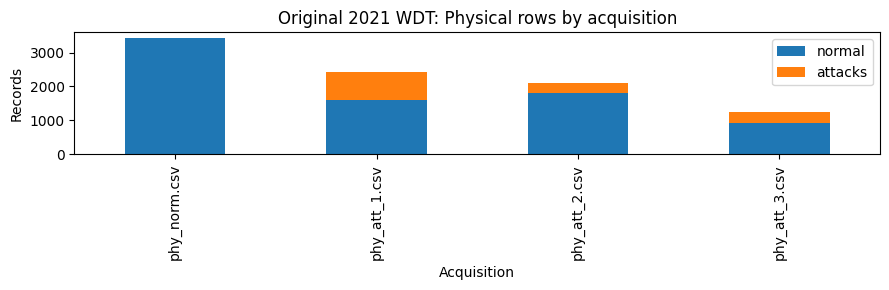

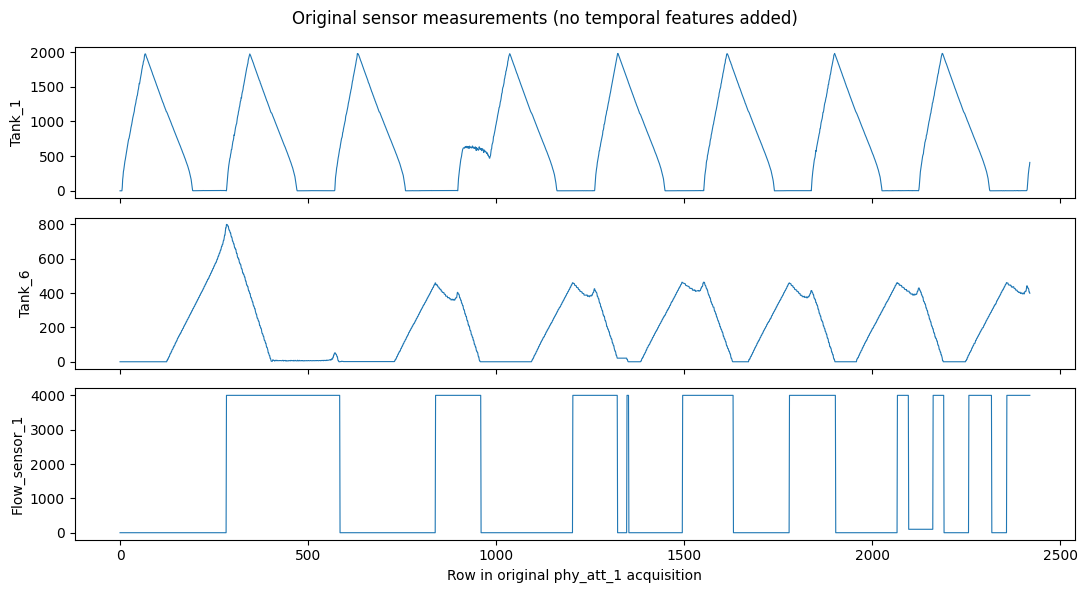

In [7]:
fig,ax=plt.subplots(figsize=(9,3))
phys_eda[['normal','attacks']].plot.bar(stacked=True,ax=ax)
ax.set(title='Original 2021 WDT: Physical rows by acquisition',ylabel='Records',xlabel='Acquisition')
plt.tight_layout();plt.savefig(OUT/'eda_physical_labels.png',dpi=160);plt.show()

# Examples of signals under the original labels; just visualization, no engineered features.
att=raw_physical[1]
show_cols=['Tank_1','Tank_6','Flow_sensor_1']
fig,axs=plt.subplots(len(show_cols),1,figsize=(11,6),sharex=True)
for ax,feat in zip(axs,show_cols):
    ax.plot(np.arange(len(att)),pd.to_numeric(att[feat],errors='coerce'),linewidth=0.8)
    ax.set_ylabel(feat)
axs[-1].set_xlabel('Row in original phy_att_1 acquisition')
fig.suptitle('Original sensor measurements (no temporal features added)')
plt.tight_layout();plt.savefig(OUT/'eda_physical_signals.png',dpi=160);plt.show()

## 3 · Paper physical baseline preparation
**Section V-B:** merge acquisitions, remove identical records, then K-Fold CV with feature standardization fitted on each training fold. Original physical measurements are the **40** sensor/actuator columns. `Time` is stored for EDA, not used as input (our disclosed choice). Attack = 1, normal = 0.

*The article does not specify the exact row-duplicate key. This notebook treats rows with identical **physical feature values AND binary labels** as duplicates, excluding the time identifier.*

In [8]:
assert not phys[PHYS_COLS].isna().any().any(), 'Original paper did not specify imputation: inspect missing physical values manually.'
features=phys[PHYS_COLS].copy()
for c in features:
    if pd.api.types.is_bool_dtype(features[c]):features[c]=features[c].astype('int8')
    else:features[c]=pd.to_numeric(features[c],errors='raise')
phys_model=features.copy()
phys_model['Label_n']=phys.Label_n.to_numpy()
rows_before=len(phys_model)
phys_model=phys_model.drop_duplicates(keep='first').reset_index(drop=True)
print('Before:',rows_before,'After removal of identical records:',len(phys_model),
      'Removed:',rows_before-len(phys_model))
assert len(phys_model)>0 and phys_model.Label_n.nunique()==2
X_phy=phys_model[PHYS_COLS].to_numpy(dtype=np.float64)
y_phy=phys_model.Label_n.to_numpy(dtype=np.int8)
assert np.isfinite(X_phy).all()
(OUT/'physical_dedup_summary.json').write_text(json.dumps({'rows_original':rows_before,
      'rows_after_dedup':len(phys_model),'features':len(PHYS_COLS),'class_counts':
      pd.Series(y_phy).value_counts().to_dict()},indent=2,default=int))

Before: 9206 After removal of identical records: 9168 Removed: 38


127

## 4 · Machine learning from **Section V** (all four published algorithms)
KNN `n_neighbors=10`; Random Forest `n_estimators=100`; SVM `kernel='rbf'`; Gaussian Naive Bayes. All standardization learned on **training rows only**.

In [9]:
def paper_estimators():
    # The paper does not list the remaining hyperparameters.
    return {
        'KNN_k10': KNeighborsClassifier(n_neighbors=10),
        'RF_100': RandomForestClassifier(n_estimators=100,random_state=RANDOM_STATE,n_jobs=-1),
        'SVM_RBF': SVC(kernel='rbf'),
        'GaussianNB': GaussianNB()}

def binary_scores(y_true,y_pred):
    return {'accuracy':accuracy_score(y_true,y_pred),
            'precision':precision_score(y_true,y_pred,pos_label=1,zero_division=0),
            'recall':recall_score(y_true,y_pred,pos_label=1,zero_division=0),
            'f1':f1_score(y_true,y_pred,pos_label=1,zero_division=0)}

def run_physical_paper_cv(X,y):
    kf=KFold(n_splits=N_SPLITS,shuffle=KF_SHUFFLE,
             random_state=RANDOM_STATE if KF_SHUFFLE else None)
    records=[]; oofs={name:np.full(len(y),-1,dtype=np.int8) for name in paper_estimators()}
    for fold,(train_idx,test_idx) in enumerate(kf.split(X),start=1):
        assert set(train_idx).isdisjoint(test_idx)
        Xtr,Xte=X[train_idx],X[test_idx]
        # Section V: scale using training-fold mean and standard deviation only.
        scaler=StandardScaler().fit(Xtr)
        a,b=scaler.transform(Xtr),scaler.transform(Xte)
        for name,clf in paper_estimators().items():
            start=time.time();clf.fit(a,y[train_idx]);pred=clf.predict(b)
            oofs[name][test_idx]=pred
            records.append({'dataset':'physical','model':name,'fold':fold,
                            'train_size':len(train_idx),'test_size':len(test_idx),
                            **binary_scores(y[test_idx],pred),
                            'seconds':round(time.time()-start,2)})
        print('Finished physical fold',fold,'/',N_SPLITS)
    fold_df=pd.DataFrame(records)
    fold_df.to_csv(OUT/'physical_paper_folds.csv',index=False)
    overall=[]
    for name,pred in oofs.items():
        assert (pred>=0).all()
        overall.append({'dataset':'physical','model':name,'n_test':len(y),**binary_scores(y,pred)})
        pd.DataFrame({'y_true':y,'y_pred':pred}).to_csv(OUT/f'physical_oof_{name}.csv',index=False)
        pd.DataFrame(confusion_matrix(y,pred,labels=[0,1]),index=['true_normal','true_attack'],
                     columns=['pred_normal','pred_attack']).to_csv(OUT/f'physical_confusion_{name}.csv')
    res=pd.DataFrame(overall).sort_values('model')
    res.to_csv(OUT/'physical_paper_pooled_metrics.csv',index=False)
    return res,fold_df

physical_results,physical_folds=run_physical_paper_cv(X_phy,y_phy)
display(physical_results.style.format({k:'{:.2%}' for k in ['accuracy','precision','recall','f1']}))

Finished physical fold 1 / 5
Finished physical fold 2 / 5
Finished physical fold 3 / 5
Finished physical fold 4 / 5
Finished physical fold 5 / 5


,dataset,model,n_test,accuracy,precision,recall,f1
3,physical,GaussianNB,9168,80.02%,34.80%,30.66%,32.60%
0,physical,KNN_k10,9168,96.29%,91.95%,83.81%,87.69%
1,physical,RF_100,9168,98.83%,98.20%,94.33%,96.22%
2,physical,SVM_RBF,9168,92.68%,92.90%,57.99%,71.41%


## 5 · Original network dataset: header QA and exploratory audit
Paper Table 5: packet-level network features, not per-second aggregations. Network source CSVs contain 16 columns: `Time`, 13 traffic fields, `label_n`, `label`. We keep only the 13 non-time packet features (disclosed interpretation).

**Important:** Source files are multi-GB. The following pipeline streams *every* row of all four CSVs, writes compressed Parquet, and uses DuckDB to remove identical records. It does not silently sample or replace the original packet-level data.

In [10]:
NET_COLS=['mac_s','mac_d','ip_s','ip_d','sport','dport','proto','flags',
          'size','modbus_fn','n_pkt_src','n_pkt_dst','modbus_response']
NET_ALL=['Time',*NET_COLS,'label_n','label']
assert len(NET_COLS)==13 and len(NET_ALL)==16
net_paths={name:original_path('network',name) for name in NETWORK_FILENAMES}
net_headers=[]
for name,path in net_paths.items():
    d=pd.read_csv(path,nrows=1000,dtype=str,keep_default_na=False,encoding='utf-8-sig')
    d.columns=d.columns.astype(str).str.strip()
    assert set(d.columns)==set(NET_ALL),f'{name}: columns unexpected: {d.columns.tolist()}'
    net_headers.append({'file':name,'size_GB':round(path.stat().st_size/1e9,3),
                        'sample_labels':d['label_n'].value_counts().to_dict(),
                        'sample_protocols':d['proto'].value_counts().head(7).to_dict()})
display(pd.DataFrame(net_headers))

Mounted folder did not contain: /content/drive/MyDrive/WDT_NETWORK/normal.csv — downloading original Drive ID: normal.csv
Downloaded: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED/intermediate_cache/original_downloads/network/normal.csv 1243223871
Mounted folder did not contain: /content/drive/MyDrive/WDT_NETWORK/attack_1.csv — downloading original Drive ID: attack_1.csv


Downloaded: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED/intermediate_cache/original_downloads/network/attack_1.csv 888243096
Mounted folder did not contain: /content/drive/MyDrive/WDT_NETWORK/attack_2.csv — downloading original Drive ID: attack_2.csv


Downloaded: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED/intermediate_cache/original_downloads/network/attack_2.csv 820958798


Mounted folder did not contain: /content/drive/MyDrive/WDT_NETWORK/attack_3.csv — downloading original Drive ID: attack_3.csv


Downloaded: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED/intermediate_cache/original_downloads/network/attack_3.csv 846853194


,file,size_GB,sample_labels,sample_protocols
0,normal.csv,1.243,{'0': 1000},"{'Modbus': 976, 'TCP': 24}"
1,attack_1.csv,0.888,{'0': 1000},"{'Modbus': 990, 'TCP': 10}"
2,attack_2.csv,0.821,{'0': 1000},"{'Modbus': 952, 'TCP': 48}"
3,attack_3.csv,0.847,{'0': 1000},"{'Modbus': 941, 'TCP': 59}"


## 6 · Stream and deduplicate all network packets (paper Section V-B)
This is expensive but **does not use an arbitrary small sample**. Repeat runs can reuse completed Parquet files. We exclude the time/acquisition column from duplicate identity because it is not an input to the model in our disclosed implementation.

In [11]:
PARTS=WORK/'network_parquet_parts';PARTS.mkdir(parents=True,exist_ok=True)
NET_UNIQUE=WORK/'network_unique.parquet'
NETWORK_QA=OUT/'network_raw_qa.json'

def write_network_parts():
    info=[]
    for filename,src in net_paths.items():
        dst=PARTS/(filename.replace('.csv','.parquet'))
        if dst.exists() and dst.stat().st_size>0:
            info.append({'file':filename,'status':'already exists','parquet_bytes':dst.stat().st_size});continue
        tmp=dst.with_suffix('.tmp.parquet')
        if tmp.exists():tmp.unlink()
        writer=None;rows=0;labels=Counter();protos=Counter();missing=Counter();t0=time.time()
        try:
            for raw in pd.read_csv(src,chunksize=NETWORK_CHUNK_SIZE,dtype=str,
                                   keep_default_na=False,encoding='utf-8-sig'):
                raw.columns=raw.columns.astype(str).str.strip()
                assert set(NET_ALL)==set(raw.columns),f'{filename}: column mismatch'
                raw=raw[NET_ALL]
                raw['label_n']=raw['label_n'].str.strip()
                assert raw['label_n'].isin(['0','1']).all(),f'{filename}: unexpected label_n values'
                labels.update(raw['label_n'].value_counts().to_dict())
                protos.update(raw['proto'].str.strip().value_counts().to_dict())
                missing.update({c:int(raw[c].str.strip().eq('').sum()) for c in NET_COLS})
                rows+=len(raw)
                # Time and Label are not used as ML features; omit from intermediate storage.
                part=raw[NET_COLS+['label_n']].copy()
                part=part.apply(lambda s:s.str.strip())
                tab=pa.Table.from_pandas(part,preserve_index=False)
                if writer is None:writer=pq.ParquetWriter(str(tmp),tab.schema,compression='zstd')
                writer.write_table(tab)
                del raw,part,tab
                if rows % (NETWORK_CHUNK_SIZE*10)==0:print(filename,'rows:',f'{rows:,}')
            if writer:writer.close();writer=None
            assert tmp.is_file()
            tmp.rename(dst)
            info.append({'file':filename,'status':'completed','raw_rows':rows,
                         'label_counts':dict(labels),'protocol_counts':dict(protos),
                         'missing_counts':dict(missing),
                         'parquet_bytes':dst.stat().st_size,'seconds':round(time.time()-t0,1)})
        finally:
            if writer:writer.close()
        print('Saved:',filename,'rows:',f'{rows:,}')
    NETWORK_QA.write_text(json.dumps(info,indent=2))
    return info

if RUN_NETWORK_EXTRACTION:
    network_audit=write_network_parts()
    display(pd.DataFrame(network_audit))
else:
    print('Network extraction disabled by explicit setting; no network results claimed.')

,file,status,parquet_bytes
0,normal.csv,already exists,19986273
1,attack_1.csv,already exists,16123565
2,attack_2.csv,already exists,14514962
3,attack_3.csv,already exists,9986066


In [12]:
if RUN_NETWORK_EXTRACTION:
    full=[x for x in network_audit if 'raw_rows' in x]
    if full:
        summary=pd.DataFrame([{'capture':r['file'],'rows':r['raw_rows'],
                               'normal':int(r['label_counts'].get('0',0)),
                               'attack':int(r['label_counts'].get('1',0))} for r in full])
        summary.to_csv(OUT/'network_raw_counts_by_capture.csv',index=False)
        display(summary)
        ax=summary.set_index('capture')[['normal','attack']].plot(kind='bar',stacked=True,figsize=(9,3))
        ax.set(title='Original network packet records by acquisition (full source)',ylabel='Packet records')
        plt.tight_layout();plt.savefig(OUT/'eda_network_label_counts.png',dpi=160);plt.show()
        protocols=Counter()
        for r in full:protocols.update(r.get('protocol_counts',{}))
        top=pd.Series(dict(protocols.most_common(12)),dtype='int64').sort_values()
        ax=top.plot(kind='barh',figsize=(9,4))
        ax.set(title='Original network protocol distribution (all streamed packets)',xlabel='Packets')
        plt.tight_layout();plt.savefig(OUT/'eda_network_protocols.png',dpi=160);plt.show()
    else:
        print('Streamed network audit uses cached Parquet; previous raw EDA is preserved on Drive.')


Streamed network audit uses cached Parquet; previous raw EDA is preserved on Drive.


In [13]:
def deduplicate_network():
    all_parts=list(PARTS.glob('*.parquet'))
    assert len(all_parts)==4, f'Expected four complete network files; found {len(all_parts)}'
    if NET_UNIQUE.exists():
        print('Using previously created network_unique.parquet:',NET_UNIQUE)
    else:
        con=duckdb.connect(str(WORK/'dedup.duckdb'))
        con.execute('SET memory_limit="6GB"')
        con.execute(f"SET temp_directory='{str(WORK/'duckdb_tmp')}'")
        src=str(PARTS/'*.parquet').replace("'","''")
        dest=str(NET_UNIQUE).replace("'","''")
        con.execute(f"COPY (SELECT DISTINCT {','.join(NET_COLS)}, label_n FROM read_parquet('{src}')) "
                    f"TO '{dest}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        con.close()
    con=duckdb.connect()
    src=str(NET_UNIQUE).replace("'","''")
    cnt=int(con.execute(f"SELECT COUNT(*) FROM read_parquet('{src}')").fetchone()[0])
    classes=con.execute(f"SELECT label_n, COUNT(*) AS n FROM read_parquet('{src}') GROUP BY label_n ORDER BY label_n").df()
    con.close()
    print('After paper-style duplicate removal:',f'{cnt:,}','network records')
    display(classes)
    (OUT/'network_unique_summary.json').write_text(json.dumps({'unique_rows':cnt,'labels':classes.to_dict('records'),
       'duplicate_key':'13 original non-time packet columns + label_n'},indent=2))
    return cnt

if RUN_NETWORK_EXTRACTION: network_unique_rows=deduplicate_network()

Using previously created network_unique.parquet: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED/intermediate_cache/network_unique.parquet
After paper-style duplicate removal: 930,647 network records


,label_n,n
0,0,724128
1,1,206519


## 7 · Network CV (same four classifiers; **no hidden sampling**)
**Computational constraint:** full RBF SVM and KNN can be infeasible with millions of packet rows on a standard Colab runtime. The default safety gate protects your session and **does not substitute a different paper method**. To insist on running all original rows, use a high-RAM runtime and explicitly set `ALLOW_EXPENSIVE_NETWORK_ML=True`; even then, SVM/KNN may take extremely long or fail. If skipped, the report will say **network not reproduced**.

Categorical fields are encoded with `OrdinalEncoder` fitted on training folds only. **Paper did not document encoding**, so the notebook flags this implementation assumption.

In [14]:
network_results=None
if not RUN_NETWORK_EXTRACTION:
    print('NETWORK: NOT RUN (explicit toggle).')
elif network_unique_rows>MAX_NETWORK_ML_ROWS and not ALLOW_EXPENSIVE_NETWORK_ML:
    print(f'NETWORK TRAINING NOT RUN: {network_unique_rows:,} unique rows exceed explicit RAM/compute safety gate '
          f'({MAX_NETWORK_ML_ROWS:,}). No sampling occurred. Network EDA and full dedup are saved.')
    (OUT/'network_training_status.json').write_text(json.dumps({'status':'NOT_RUN_RESOURCE_SAFETY',
          'unique_rows':network_unique_rows,'gate':MAX_NETWORK_ML_ROWS,
          'reason':'Full packet-level KNN and RBF SVM may exceed available Colab resources; no subsampling performed.'},indent=2))
else:
    con=duckdb.connect()
    src=str(NET_UNIQUE).replace("'","''")
    net_df=con.execute(f"SELECT * FROM read_parquet('{src}')").df()
    con.close()
    y_net=pd.to_numeric(net_df.pop('label_n'),errors='raise').to_numpy(dtype=np.int8)
    assert set(np.unique(y_net))<=set([0,1])
    # Original attributes only; not engineered packet features.
    numeric_cols=['size','n_pkt_src','n_pkt_dst']
    cat_cols=[c for c in NET_COLS if c not in numeric_cols]
    for c in numeric_cols:net_df[c]=pd.to_numeric(net_df[c],errors='coerce')
    net_records=[];net_oofs={name:np.full(len(y_net),-1,dtype=np.int8) for name in paper_estimators()}
    splitter=KFold(n_splits=N_SPLITS,shuffle=KF_SHUFFLE,
                    random_state=RANDOM_STATE if KF_SHUFFLE else None)
    for fold,(train,test) in enumerate(splitter.split(net_df),start=1):
        x_train,x_test=net_df.iloc[train],net_df.iloc[test]
        # The paper does not specify imputation: abort instead of inventing a fill policy.
        if x_train[numeric_cols].isna().any().any() or x_test[numeric_cols].isna().any().any():
            raise ValueError('Missing numeric network values: original paper does not specify an imputation rule.')
        pre=ColumnTransformer([
           ('num','passthrough',numeric_cols),
           ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat_cols)],
            sparse_threshold=0)
        a=pre.fit_transform(x_train)
        b=pre.transform(x_test)
        # Scale the transformed attributes with training-set statistics only.
        scaler=StandardScaler().fit(a)
        a=scaler.transform(a);b=scaler.transform(b)
        for name,clf in paper_estimators().items():
            t0=time.time();clf.fit(a,y_net[train]);pred=clf.predict(b)
            net_oofs[name][test]=pred
            net_records.append({'dataset':'network','model':name,'fold':fold,
                 'train_size':len(train),'test_size':len(test),
                 **binary_scores(y_net[test],pred),'seconds':time.time()-t0})
        print('Finished network fold',fold,'/',N_SPLITS)
    pd.DataFrame(net_records).to_csv(OUT/'network_paper_folds.csv',index=False)
    network_results=pd.DataFrame([{'dataset':'network','model':name,'n_test':len(y_net),
       **binary_scores(y_net,pr)} for name,pr in net_oofs.items()])
    network_results.to_csv(OUT/'network_paper_pooled_metrics.csv',index=False)
    display(network_results.style.format({c:'{:.2%}' for c in ['accuracy','precision','recall','f1']}))
    (OUT/'network_training_status.json').write_text(json.dumps({'status':'COMPLETE','rows':len(y_net)},indent=2))

NETWORK TRAINING NOT RUN: 930,647 unique rows exceed explicit RAM/compute safety gate (350,000). No sampling occurred. Network EDA and full dedup are saved.


## 8 · Outputs and comparison rules
Use **Table 6 in the actual 2021 paper** to compare Accuracy / Precision / Recall / F1 for each method and each **separate dataset**. The article specifies KNN `k=10` neighbors but does not provide the **CV fold count**, split seed, or network categorical encoding, so treat mismatch as methodological uncertainty until those are resolved. Do not compare this baseline directly with Stage 15/16 multi-class LOCO results: evaluation protocols differ.

In [15]:
manifest={
 'paper_doi':'10.1109/ACCESS.2021.3109465',
 'physical_reproduced':physical_results is not None,
 'physical_rows_after_dedup':int(len(y_phy)),
 'network_extraction_completed':bool(RUN_NETWORK_EXTRACTION and NET_UNIQUE.exists()),
 'network_models_reproduced':network_results is not None,
 'network_unique_rows':int(network_unique_rows) if RUN_NETWORK_EXTRACTION else None,
 'number_of_folds_assumed':N_SPLITS,
 'paper_comparison_caveat':'KNN k=10 means nearest neighbors (NOT CV folds); authors did not disclose CV fold count, random seed, network encoding; Time excluded as identifier.',
 'raw_sources':{'physical':list(physical_paths),'network':list(net_paths) if RUN_NETWORK_EXTRACTION else []},
 'runtime':{'python':sys.version.split()[0],'pandas':pd.__version__,
             'sklearn':__import__('sklearn').__version__},
 'result_dir':str(OUT)
}
(OUT/'FINAL_STATUS.json').write_text(json.dumps(manifest,indent=2))
print(json.dumps(manifest,indent=2))
print('All completed outputs saved to:',OUT)

{
  "paper_doi": "10.1109/ACCESS.2021.3109465",
  "physical_reproduced": true,
  "physical_rows_after_dedup": 9168,
  "network_extraction_completed": true,
  "network_models_reproduced": false,
  "network_unique_rows": 930647,
  "number_of_folds_assumed": 5,
  "paper_comparison_caveat": "KNN k=10 means nearest neighbors (NOT CV folds); authors did not disclose CV fold count, random seed, network encoding; Time excluded as identifier.",
  "raw_sources": {
    "physical": [
      "phy_norm.csv",
      "phy_att_1.csv",
      "phy_att_2.csv",
      "phy_att_3.csv"
    ],
    "network": [
      "normal.csv",
      "attack_1.csv",
      "attack_2.csv",
      "attack_3.csv"
    ]
  },
  "runtime": {
    "python": "3.13.16",
    "pandas": "2.2.3",
    "sklearn": "1.6.1"
  },
  "result_dir": "/content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED"
}
All completed outputs saved to: /content/drive/MyDrive/OT_SENTINEL_RESULTS/WDT_ORIGINAL_PAPER_BASELINE_V2_AUDITED


## Paper-faithfulness checklist (for the supervisor)
| Item | 2021 paper | This notebook |
|---|---|---|
| Datasets | Four acquisitions, physical & network separately | ✅ Four, separately |
| Label | Binary normal / attack | ✅ `Label_n`/`label_n` (corrects `Lable_n` typo) |
| Models | KNN, RF, SVM, Gaussian NB | ✅ Same four |
| KNN/RF parameters | k=10 / 100 trees | ✅ Same |
| SVM/NB | RBF / Gaussian | ✅ Same |
| Standardization | Train fit, test transform | ✅ Same |
| Identical records | Removed | ✅ Removed; chosen duplicate key documented |
| Cross-validation | K-Fold, **fold count not stated**; KNN **k=10 neighbors** | ⚠️ **5 CV folds is our assumption**, unrelated to KNN k=10 |
| Network categorical encoding | Not specified | ⚠️ Fold-local ordinal encoding is our choice |
| Time handling | Not specified | ⚠️ Exclude identifier as disclosed choice |
| Network model full run | All rows | ⚠️ Requires enough RAM/compute; no hidden subsampling |
| EDA | Dataset labels/features/graphs | ✅ Additional descriptive plots, not model features |

**Methodological caution:** Conventional K-Fold shuffles rows across time and potentially across acquisitions. That is what is described in the paper's baseline, but it is **not a leakage-proof forward-time or capture-held-out evaluation**. We reproduce the published methodology first; a stricter validation protocol belongs in a *separate follow-up experiment*, not in this baseline.